# Massive MIMO 64×8 — Version 2 Complete Notebook
**QPSK / 16-QAM / 64-QAM | Pilot LS/LMMSE | MRC/ZF/MMSE | Spatial correlation | Multipath OFDM | Doppler | BER/SE/EE**

This notebook upgrades the baseline project. It includes a correlated frequency-selective Rayleigh channel, large-scale fading, time evolution, orthogonal pilot estimation, three linear detectors, higher-order QAM, detector-specific post-detection SINR, an illustrative hardware power model, and validation.

**Honest scope:** this is a research-oriented simulation framework, not a complete 3GPP-compliant simulator. Doppler is approximated by an AR(1) process; pilots are assumed orthogonal; the power model is illustrative; and SE is an SINR-based proxy, not coded throughput.

## 1. Imports and parameters

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from math import erfc
from time import time
rng = np.random.default_rng(2026)
plt.rcParams["figure.figsize"] = (8,5)

M, K = 64, 8                 # BS antennas, uplink users
N_SC, N_TAPS = 8, 4          # OFDM subcarriers and multipath taps
N_BLOCKS = 30               # increase to 100+ for final results
COHERENCE_SYMBOLS = 20
SNR_DB = np.arange(0, 31, 5)
MODULATIONS = {"QPSK":4, "16-QAM":16, "64-QAM":64}
DETECTORS = ["MRC","ZF","MMSE"]
ESTIMATORS = ["LS","LMMSE"]

RHO = 0.35                  # exponential ULA spatial correlation
PATHLOSS_EXP = 3.5
SHADOW_STD_DB = 6.0
CARRIER_HZ = 3.5e9
SPEED_KMH = 30.0
BLOCK_SECONDS = 1e-3
PILOT_TO_DATA_POWER = 1.0

## 2. QAM mapper/demapper (Gray-labelled square QAM)

In [19]:
def bps(Q): return int(np.log2(Q))

def qam_mod(bits, Q):
    bits = np.asarray(bits, dtype=np.int8).reshape(-1)
    k = bps(Q); na = k//2; L = int(np.sqrt(Q))
    if Q not in (4,16,64) or len(bits)%k:
        raise ValueError("Use Q=4,16,64 and a bit count divisible by log2(Q).")
    B = bits.reshape(-1,k)
    w = 2**np.arange(na-1,-1,-1)
    bi = (B[:,:na]*w).sum(axis=1).astype(int)
    bq = (B[:,na:]*w).sum(axis=1).astype(int)
    gi, gq = bi^(bi>>1), bq^(bq>>1)
    norm = np.sqrt(2*(Q-1)/3)
    return ((2*gi-(L-1)) + 1j*(2*gq-(L-1)))/norm

def gray_to_binary(g):
    b = g.copy().astype(int)
    shift = 1
    while shift < 8:
        b ^= b >> shift
        shift *= 2
    return b

def qam_demod(z, Q):
    z=np.asarray(z).reshape(-1); k=bps(Q); na=k//2; L=int(np.sqrt(Q))
    norm=np.sqrt(2*(Q-1)/3); w=2**np.arange(na-1,-1,-1)
    def decode(v):
        g=np.rint((v*norm+(L-1))/2).astype(int)
        return gray_to_binary(np.clip(g,0,L-1))
    bi,bq=decode(z.real),decode(z.imag)
    out=np.zeros((len(z),k),dtype=np.int8)
    for j in range(na):
        out[:,j]=(bi//w[j])%2
        out[:,na+j]=(bq//w[j])%2
    return out.reshape(-1)

for name,Q in MODULATIONS.items():
    bits=rng.integers(0,2,1000*bps(Q),dtype=np.int8)
    assert np.array_equal(bits,qam_demod(qam_mod(bits,Q),Q))
    print(name,"noiseless modem check passed")

QPSK noiseless modem check passed
16-QAM noiseless modem check passed
64-QAM noiseless modem check passed


## 3. Large-scale fading and spatially correlated ULA

Distances m: [ 95.8 167.6 143.3 215.3 212.5  63.3 209.6  79.9]
Normalized beta: [1.400e-01 6.900e-02 1.200e-02 2.000e-03 1.900e-02 7.244e+00 1.000e-03
 5.130e-01]


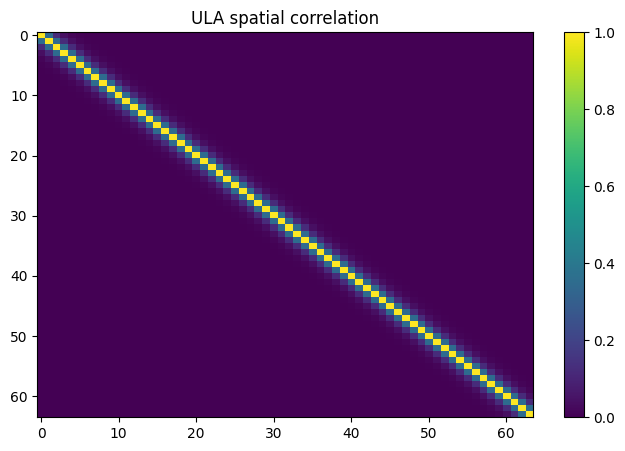

In [20]:
def make_beta(K, rng):
    d=rng.uniform(50,250,K)                 # user distances in metres
    shadow=rng.normal(0,SHADOW_STD_DB,K)
    rel_loss=10*PATHLOSS_EXP*np.log10(d/100)+shadow
    beta=10**(-rel_loss/10)
    return d, shadow, beta/np.mean(beta)    # normalized mean beta = 1

def corr_sqrt(M,rho):
    idx=np.arange(M)
    R=rho**np.abs(idx[:,None]-idx[None,:])
    ev,U=np.linalg.eigh(R)
    Rs=U@np.diag(np.sqrt(np.maximum(ev,1e-12)))@U.conj().T
    return R,Rs

distances,shadow_db,beta=make_beta(K,rng)
R,Rs=corr_sqrt(M,RHO)
print("Distances m:",np.round(distances,1))
print("Normalized beta:",np.round(beta,3))
plt.imshow(np.abs(R),aspect="auto"); plt.colorbar(); plt.title("ULA spatial correlation"); plt.show()

## 4. Multipath frequency-selective channel and Doppler evolution

In [21]:
pdp=np.exp(-np.arange(N_TAPS)); pdp=pdp/pdp.sum()
speed=SPEED_KMH/3.6
fd=speed/(3e8/CARRIER_HZ)
# J0(x) power-series approximation for Doppler correlation
def j0_approx(x):
    term=1.0; total=1.0
    for n in range(1,30):
        term *= -(x*x/4)/(n*n); total += term
        if abs(term)<1e-13: break
    return total
alpha=float(np.clip(j0_approx(2*np.pi*fd*BLOCK_SECONDS),-0.99,0.99))
print("Doppler Hz:",round(fd,2),"AR(1) correlation:",round(alpha,4),"PDP:",np.round(pdp,3))

def new_taps(beta,Rs,pdp,rng):
    L=len(pdp); M=Rs.shape[0]; K=len(beta)
    h=np.empty((L,M,K),complex)
    for l in range(L):
        for k in range(K):
            z=(rng.normal(size=M)+1j*rng.normal(size=M))/np.sqrt(2)
            h[l,:,k]=np.sqrt(beta[k]*pdp[l])*(Rs@z)
    return h

def evolve_taps(old,beta,Rs,pdp,alpha,rng):
    return alpha*old+np.sqrt(max(0,1-alpha**2))*new_taps(beta,Rs,pdp,rng)

def channel_on_sc(taps,n,N):
    ph=np.exp(-1j*2*np.pi*n*np.arange(taps.shape[0])/N)
    return np.einsum("lmk,l->mk",taps,ph)

Doppler Hz: 97.22 AR(1) correlation: 0.9089 PDP: [0.644 0.237 0.087 0.032]


## 5. Orthogonal pilots: LS and LMMSE channel estimation

In [22]:
def make_lmmse_filters(beta,R,pilot_power,noise_var):
    # Precompute one MxM LMMSE filter per user/SNR; reused across blocks/subcarriers.
    M=len(R)
    I=np.eye(M)
    filters=[]
    for k in range(len(beta)):
        Rk=beta[k]*R
        A=pilot_power*Rk+noise_var*I
        filters.append(np.sqrt(pilot_power)*Rk@np.linalg.solve(A,I))
    return filters

def estimate_pilot(H,beta,R,pilot_power,noise_var,method,rng,lmmse_filters=None):
    M,K=H.shape
    noise=(rng.normal(size=(M,K))+1j*rng.normal(size=(M,K)))*np.sqrt(noise_var/2)
    Yp=np.sqrt(pilot_power)*H+noise
    if method=="LS":
        return Yp/np.sqrt(pilot_power)
    if method=="LMMSE":
        if lmmse_filters is None:
            lmmse_filters=make_lmmse_filters(beta,R,pilot_power,noise_var)
        Hhat=np.zeros_like(H)
        for k in range(K):
            Hhat[:,k]=lmmse_filters[k]@Yp[:,k]
        return Hhat
    raise ValueError("method must be LS or LMMSE")

## 6. MRC, ZF, MMSE and actual post-detection SINR

In [23]:
def make_weights(Hhat,noise_eff):
    M,K=Hhat.shape
    gram=Hhat.conj().T@Hhat
    I=np.eye(K)
    loading=1e-10*max(1.0,np.real(np.trace(gram))/K)
    return {
        "MRC":Hhat.conj().T,
        "ZF":np.linalg.solve(gram+loading*I,Hhat.conj().T),
        "MMSE":np.linalg.solve(gram+(noise_eff+loading)*I,Hhat.conj().T)
    }

def post_sinr(W,Htrue,noise_eff):
    G=W@Htrue
    desired=np.abs(np.diag(G))**2
    interf=np.maximum(np.sum(np.abs(G)**2,axis=1)-desired,0)
    noise=noise_eff*np.sum(np.abs(W)**2,axis=1)
    return desired/np.maximum(interf+noise,1e-15)

## 7. Transparent illustrative power model

In [24]:
# PLACEHOLDER values: replace with measured/datasheet values for a paper.
POWER = {
    "static_W":80.0, "RF_W_per_antenna":0.8,
    "BB_W_per_MK":0.015, "UE_W_per_user":0.1,
    "PA_efficiency":0.35,
    "detector_extra_W":{"MRC":0.0,"ZF":1.0,"MMSE":1.5}
}
def total_power(det,M,K):
    return (POWER["static_W"]+M*POWER["RF_W_per_antenna"]
            +M*K*POWER["BB_W_per_MK"]
            +K*POWER["UE_W_per_user"]/POWER["PA_efficiency"]
            +POWER["detector_extra_W"][det])
for d in DETECTORS: print(d,total_power(d,M,K),"W (illustrative)")

MRC 141.16571428571427 W (illustrative)
ZF 142.16571428571427 W (illustrative)
MMSE 142.66571428571427 W (illustrative)


## 8. Full Monte Carlo simulation

In [25]:
def simulate(M=64,K=8,Nsc=8,Ntap=4,nblocks=30,snr_db_values=SNR_DB,
             mods=MODULATIONS,estimators=ESTIMATORS,detectors=DETECTORS,seed=2026):
    rg=np.random.default_rng(seed)
    Rloc,Rsloc=corr_sqrt(M,RHO)
    _,_,bet=make_beta(K,rg)
    delay=np.exp(-np.arange(Ntap)); delay/=delay.sum()
    v=SPEED_KMH/3.6; fD=v/(3e8/CARRIER_HZ)
    a=float(np.clip(j0_approx(2*np.pi*fD*BLOCK_SECONDS),-.99,.99))
    pilot_factor=max(0,1-K/COHERENCE_SYMBOLS)
    cp_factor=max(0,1-(Ntap-1)/Nsc)
    out={(mn,est,det):{"ber":[],"se":[],"ee":[],"sinr_db":[]}
         for mn in mods for est in estimators for det in detectors}

    for snrdb in snr_db_values:
        p=10**(snrdb/10); nv=1.0; neff=nv/p
        # Precompute LMMSE filters once per SNR (avoids repeated matrix solves).
        lmmse_filters=make_lmmse_filters(bet,Rloc,p,nv)
        taps=new_taps(bet,Rsloc,delay,rg)
        acc={key:{"err":0,"bits":0,"se":0.0,"sinr":0.0,"n":0} for key in out}
        for block in range(nblocks):
            if block: taps=evolve_taps(taps,bet,Rsloc,delay,a,rg)
            for sc in range(Nsc):
                H=channel_on_sc(taps,sc,Nsc)
                Hests={e:estimate_pilot(H,bet,Rloc,p,nv,e,rg,lmmse_filters) for e in estimators}
                for mn,Q in mods.items():
                    bps=bps_func(Q)
                    txbits=rg.integers(0,2,K*bps,dtype=np.int8)
                    x=qam_mod(txbits,Q)
                    noise=(rg.normal(size=M)+1j*rg.normal(size=M))*np.sqrt(nv/2)
                    y=(np.sqrt(p)*(H@x)+noise)/np.sqrt(p)
                    for est in estimators:
                        Ws=make_weights(Hests[est],neff)
                        for det in detectors:
                            W=Ws[det]
                            raw=W@y
                            # Equalize using estimated effective channel gain
                            gain=np.diag(W@Hests[est])
                            xeq=raw/np.where(np.abs(gain)>1e-12,gain,1e-12)
                            bhat=qam_demod(xeq,Q)
                            key=(mn,est,det); a0=acc[key]
                            a0["err"]+=np.sum(txbits!=bhat); a0["bits"]+=len(txbits)
                            sinr=np.clip(post_sinr(W,H,neff),0,1e12)
                            a0["sinr"]+=np.sum(sinr); a0["n"]+=K
                            # Gaussian-input SINR proxy capped by QAM bits/symbol
                            a0["se"]+=np.sum(np.minimum(np.log2(1+sinr),bps))
        for key,a0 in acc.items():
            mn,est,det=key
            ber=a0["err"]/max(a0["bits"],1)
            mean_sinr=a0["sinr"]/max(a0["n"],1)
            gross=a0["se"]/(nblocks*Nsc)
            net=gross*pilot_factor*cp_factor
            out[key]["ber"].append(ber)
            out[key]["se"].append(net)
            out[key]["ee"].append(net/total_power(det,M,K))
            out[key]["sinr_db"].append(10*np.log10(max(mean_sinr,1e-15)))
        print("Finished SNR",snrdb,"dB")
    return out,{"beta":bet,"doppler_alpha":a,"fd_hz":fD,
                "pilot_factor":pilot_factor,"cp_factor":cp_factor}

def bps_func(Q): return int(np.log2(Q))

t0=time()
results,meta=simulate()
print("Elapsed seconds:",round(time()-t0,1))

Finished SNR 0 dB
Finished SNR 5 dB
Finished SNR 10 dB
Finished SNR 15 dB
Finished SNR 20 dB
Finished SNR 25 dB
Finished SNR 30 dB
Elapsed seconds: 17.3


## 9. BER plots — QPSK, 16-QAM, 64-QAM (LMMSE CSI)

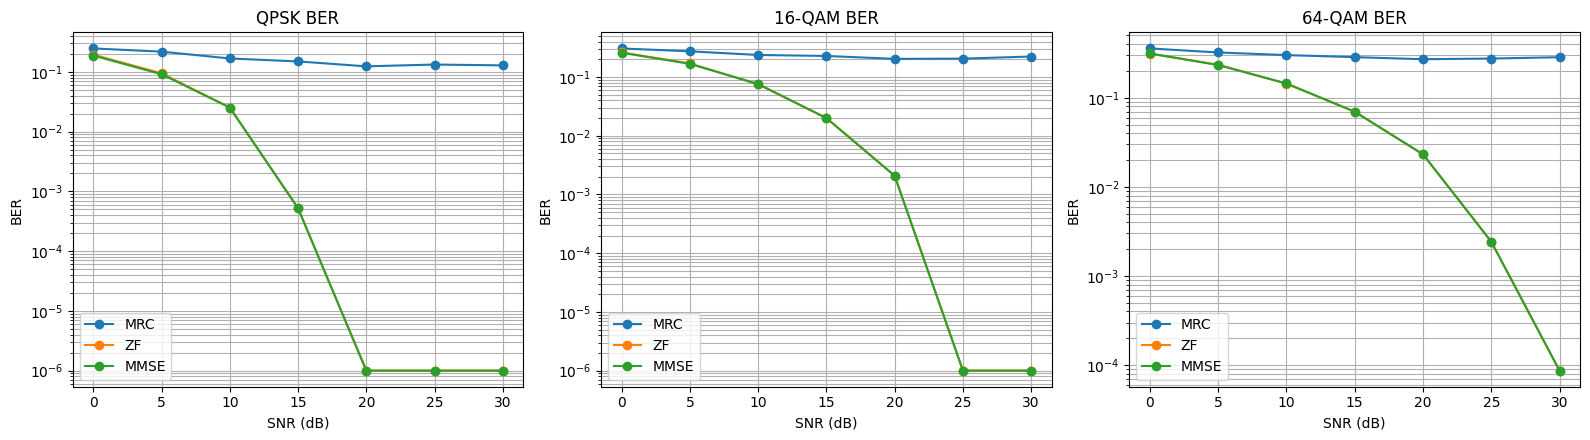

In [26]:
fig,axs=plt.subplots(1,3,figsize=(16,4.5))
for ax,(mn,Q) in zip(axs,MODULATIONS.items()):
    for det in DETECTORS:
        v=results[(mn,"LMMSE",det)]["ber"]
        ax.semilogy(SNR_DB,np.maximum(v,1e-6),marker="o",label=det)
    ax.set_title(mn+" BER"); ax.set_xlabel("SNR (dB)"); ax.set_ylabel("BER")
    ax.grid(True,which="both"); ax.legend()
plt.tight_layout(); plt.show()

## 10. LS versus LMMSE channel estimation (64-QAM)

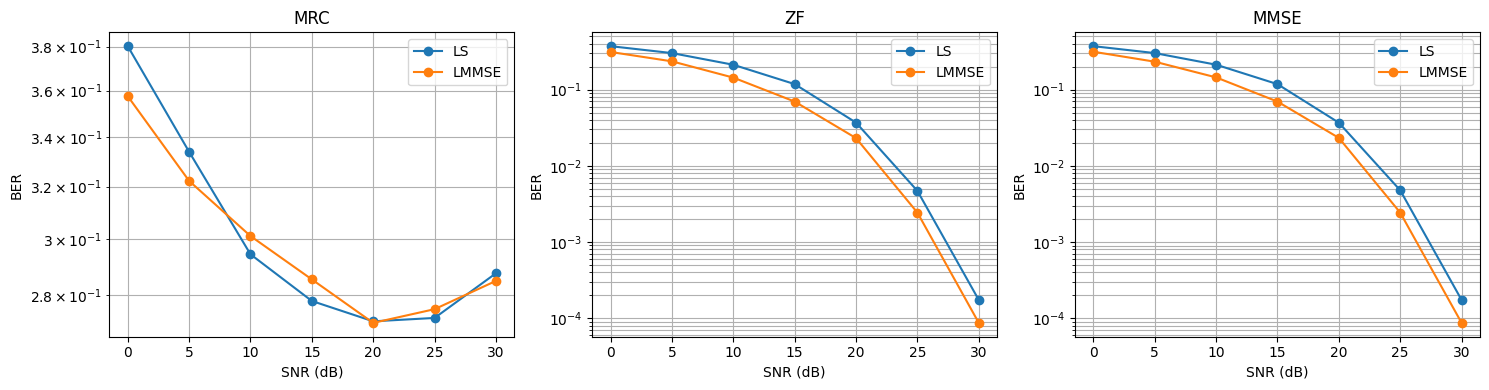

In [27]:
fig,axs=plt.subplots(1,3,figsize=(15,4))
for ax,det in zip(axs,DETECTORS):
    for est in ESTIMATORS:
        v=results[("64-QAM",est,det)]["ber"]
        ax.semilogy(SNR_DB,np.maximum(v,1e-6),marker="o",label=est)
    ax.set_title(det); ax.set_xlabel("SNR (dB)"); ax.set_ylabel("BER")
    ax.grid(True,which="both"); ax.legend()
plt.tight_layout(); plt.show()

## 11. Spectral efficiency proxy

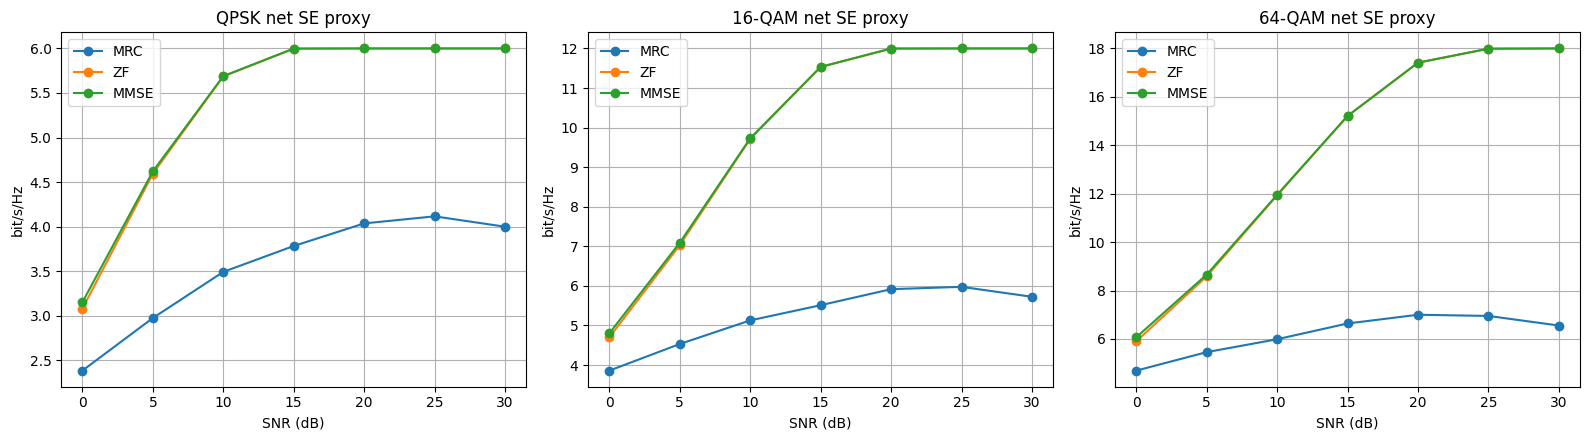

In [28]:
fig,axs=plt.subplots(1,3,figsize=(16,4.5))
for ax,(mn,Q) in zip(axs,MODULATIONS.items()):
    for det in DETECTORS:
        ax.plot(SNR_DB,results[(mn,"LMMSE",det)]["se"],marker="o",label=det)
    ax.set_title(mn+" net SE proxy"); ax.set_xlabel("SNR (dB)")
    ax.set_ylabel("bit/s/Hz"); ax.grid(); ax.legend()
plt.tight_layout(); plt.show()

## 12. Energy efficiency proxy

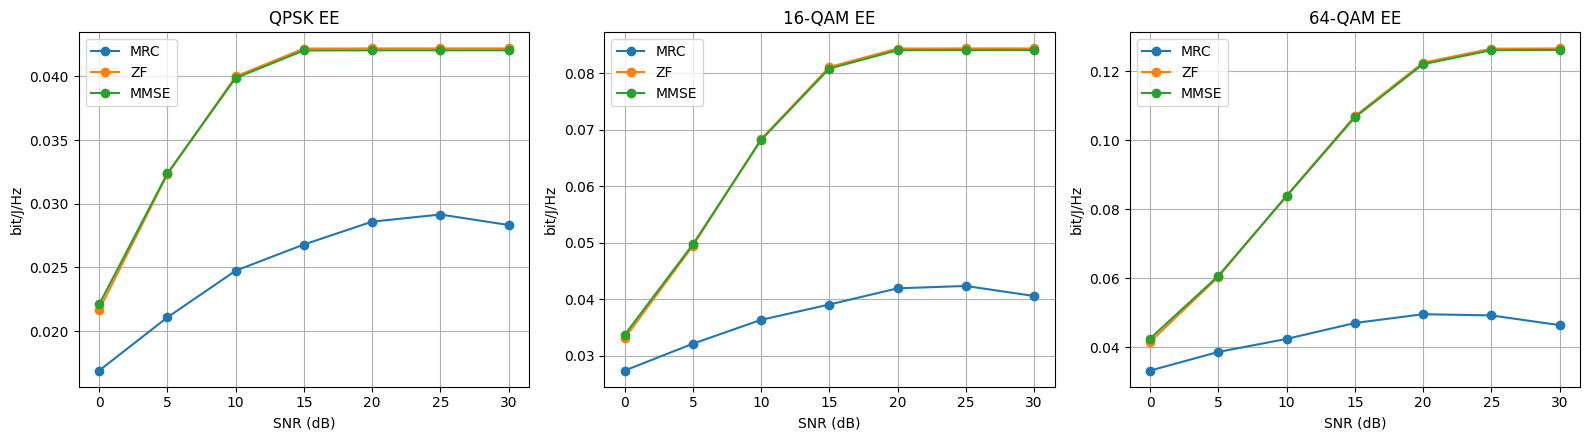

In [29]:
fig,axs=plt.subplots(1,3,figsize=(16,4.5))
for ax,(mn,Q) in zip(axs,MODULATIONS.items()):
    for det in DETECTORS:
        ax.plot(SNR_DB,results[(mn,"LMMSE",det)]["ee"],marker="o",label=det)
    ax.set_title(mn+" EE"); ax.set_xlabel("SNR (dB)")
    ax.set_ylabel("bit/J/Hz"); ax.grid(); ax.legend()
plt.tight_layout(); plt.show()

## 13. Adaptive modulation illustration

In [30]:
# Example SINR thresholds ONLY. Calibrate against a target BER/BLER in research work.
ADAPT_THRESHOLDS_DB={"16QAM":10.0,"64QAM":18.0}
def choose_modulation(sinr_db):
    if sinr_db>=ADAPT_THRESHOLDS_DB["64QAM"]: return "64-QAM"
    if sinr_db>=ADAPT_THRESHOLDS_DB["16QAM"]: return "16-QAM"
    return "QPSK"
for x in [-2,4,11,16,21,27]:
    print(x,"dB ->",choose_modulation(x))

-2 dB -> QPSK
4 dB -> QPSK
11 dB -> 16-QAM
16 dB -> 16-QAM
21 dB -> 64-QAM
27 dB -> 64-QAM


## 14. Optional antenna-count comparison

In [31]:
# Set True to run a smaller extra experiment (may take time).
RUN_ANTENNA_SWEEP=False
if RUN_ANTENNA_SWEEP:
    antenna_sweep={}
    for mtest in [32,64,128]:
        rr,_=simulate(M=mtest,K=K,Nsc=N_SC,Ntap=N_TAPS,nblocks=10,
                      snr_db_values=[5,15,25],mods={"64-QAM":64},
                      estimators=["LMMSE"],detectors=DETECTORS,seed=2026+mtest)
        antenna_sweep[mtest]=rr

## 15. Numerical conditioning check

In [32]:
t_demo=new_taps(beta,Rs,pdp,rng)
H_demo=channel_on_sc(t_demo,0,N_SC)
G=H_demo.conj().T@H_demo
print("Condition number of H^H H:",np.linalg.cond(G))
print("ZF/MMSE use numpy.linalg.solve rather than explicitly forming an inverse.")

Condition number of H^H H: 22105.37553756707
ZF/MMSE use numpy.linalg.solve rather than explicitly forming an inverse.


## 16. AWGN theoretical reference for square QAM

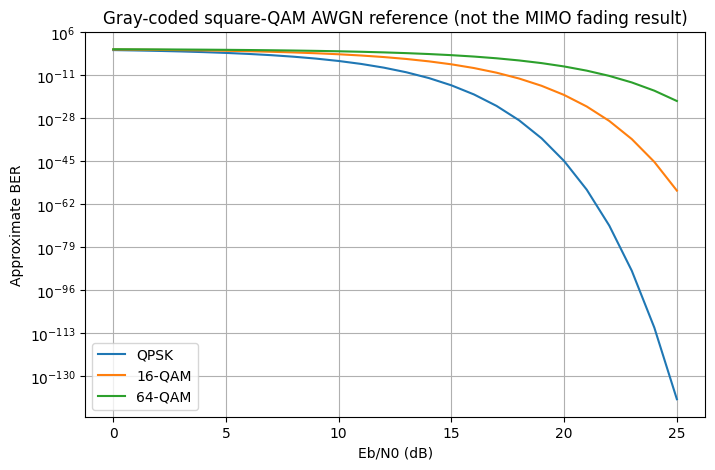

In [33]:
def Qfun(x): return 0.5*np.vectorize(erfc)(x/np.sqrt(2))
def qam_awgn_ber_approx(Q,ebn0_db):
    k=np.log2(Q); ebn0=10**(np.asarray(ebn0_db)/10)
    z=np.sqrt(3*k/(Q-1)*ebn0)
    return (4/k)*(1-1/np.sqrt(Q))*Qfun(z)

eb=np.arange(0,26)
for name,Q in MODULATIONS.items():
    plt.semilogy(eb,qam_awgn_ber_approx(Q,eb),label=name)
plt.xlabel("Eb/N0 (dB)"); plt.ylabel("Approximate BER")
plt.title("Gray-coded square-QAM AWGN reference (not the MIMO fading result)")
plt.grid(True,which="both"); plt.legend(); plt.show()

## 17. Version 1 limitations addressed

| Version 1 limitation | Version 2 improvement |
|---|---|
| i.i.d. Rayleigh only | Spatial correlation, multipath taps, large-scale fading |
| Artificial CSI error | Orthogonal pilots, LS and LMMSE estimates |
| Simplified SINR | Per-user post-detection SINR from true channel and receiver weights |
| Fixed arbitrary power | Separated static, RF, baseband, UE and detector power terms |
| QPSK only | QPSK, 16-QAM, 64-QAM |
| No mobility | Doppler-correlated block-to-block channel evolution |
| Flat fading only | Frequency response over OFDM-like subcarriers |
| Fixed antenna count | Configurable M and optional 32/64/128 sweep |
| Explicit inverse | Stable linear solves and condition-number check |
| Limited validation | Noiseless modem checks and AWGN reference curves |

## 18. Model Assumptions, Scope, and Future Research Directions
- This is not a full 3GPP TR 38.901 channel implementation.
- Doppler is an AR(1) approximation to Jakes temporal correlation.
- Orthogonal pilots are assumed; pilot contamination and pilot reuse are not included.
- A representative data symbol is simulated per coherence block; full OFDM framing, synchronization, ICI and channel coding are omitted.
- The SE is an SINR-based proxy, not a rigorously derived achievable-rate bound or coded throughput.
- The power model contains placeholder values; calibrate from datasheets or measured hardware.
- Antenna mutual coupling, RF impairments, phase noise, quantization, nonlinear PAs and scheduling are omitted.
- Adaptive-modulation thresholds are examples and must be calibrated for a target BER/BLER.

**Suggested Version 3:** pilot contamination and pilot assignment; Cell-Free Massive MIMO; power control; realistic O-RAN/RIC control; AI-based energy-aware resource allocation.

## 19. Export simulation results to CSV

In [34]:
import csv
csv_file="massive_mimo_v2_results.csv"
with open(csv_file,"w",newline="") as f:
    w=csv.writer(f)
    w.writerow(["Modulation","Estimator","Detector","SNR_dB","BER","SE_bit_s_Hz","EE_bit_J_Hz","Mean_post_SINR_dB"])
    for (mn,est,det),v in results.items():
        for i,snr in enumerate(SNR_DB):
            w.writerow([mn,est,det,snr,v["ber"][i],v["se"][i],v["ee"][i],v["sinr_db"][i]])
print("Saved",csv_file)

Saved massive_mimo_v2_results.csv
